# Monty Hall problem using Monte Carlo Method

## The idea

You are on a TV game show. In front of you, three doors: behind one of them a **car**, behind the two others a **goat**. (We assume you prefer the car. No offence to the goats.)

1. You pick a door, say door 0.
2. The host, Monty, **who knows where the car is**, opens one of the two other doors and reveals a goat. He never opens your door, and he never reveals the car (that would ruin the show).
3. Monty smiles and asks: *"Do you want to keep your door, or switch to the other closed one?"*

Two doors left, one car: surely it is 50 / 50, so who cares? **Wrong.** Switching wins **2 times out of 3**. This answer famously made thousands of readers (including a few PhDs) write angry letters to Marilyn vos Savant in 1990. Instead of writing letters, we will just play the game a few billion times.

**Why 2/3, in one sentence:** your first pick is right with probability $1/3$, and staying wins only in that case. In the other $2/3$ of the games your first pick was a goat, Monty is *forced* to open the only other goat door, and the remaining closed door is the car. So

$$P(\text{win} \mid \text{stay}) = \frac{1}{3}, \qquad P(\text{win} \mid \text{switch}) = \frac{2}{3}$$

Monty is not giving you a random door: he is giving you information.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

## One game

Doors are numbered 0, 1, 2. We draw where the car is (`win`) and the player's pick (`choice`), then Monty opens a door that is neither the car nor the player's pick. If the player already picked the car, Monty has two goats to choose from and picks one at random; otherwise he has exactly one option.

**The little trick for the remaining door:** $0 + 1 + 2 = 3$, so once we know two of the doors, the third one is simply

$$\text{rest} = 3 - \text{choice} - \text{opened}$$

No `if`, no list, just arithmetic. Run the cell a few times and watch the goats move around.

In [13]:
rng = np.random.default_rng()

win     = rng.integers(0, 3)
choice  = rng.integers(0, 3)

possible_doors = [p for p in range(3) if p != win and p != choice]
opened = rng.choice(possible_doors)                                # Monty opens a goat door that is not the player's

x = (choice == win).astype(int)                                    # 1 if staying wins
rest = 3 - choice - opened                                         # 0 + 1 + 2 = 3, so the last door is what is left
y = (rest == win).astype(int)                                      # 1 if switching wins

print(f"Win: {win}, Choice: {choice}, Open: {opened}, Rest: {rest}")
print(f"Win by staying: {x}, Win by switching: {y}")

Win: 2, Choice: 0, Open: 1, Rest: 2
Win by staying: 0, Win by switching: 1


## Many games

Same thing for $N$ games at once. Each game gives two "yes / no" results: `x` (did staying win?) and `y` (did switching win?). The win rates are just the means of `x` and `y`.

Notice that in every single game **exactly one** of the two strategies wins: `y = 1 - x`. There is no draw, and no game where both lose: the car is behind either your door or the other closed one.

In [14]:
def step(N):
    win     = rng.integers(0, 3, size=N)
    choice  = rng.integers(0, 3, size=N)

    opened = np.empty(N, dtype=int)
    for i in range(N):
        possible_doors = [p for p in range(3) if p != win[i] and p != choice[i]]
        opened[i] = rng.choice(possible_doors)

    x = (choice == win).astype(int)
    rest = 3 - choice - opened
    y = (rest == win).astype(int)

    return x, y

In [15]:
x,y = step(1000)
print(f"Win by staying: {x.mean()}, Win by switching: {y.mean()}")

Win by staying: 0.347, Win by switching: 0.653


## How sure are we?

Each game is a coin flip with an unknown probability $p$ of winning. With $N$ games, the win rate $\hat p$ has a standard error of $\sqrt{\hat p(1-\hat p)/N}$, and multiplying by $1.96$ gives a **95 % confidence interval**:

$$\hat p \pm 1.96\sqrt{\frac{\hat p(1-\hat p)}{N}}$$

For the difference "switch minus stay" we use the spread of `y - x` directly, because the two results come from the **same** games (and are perfectly anti-correlated, see above). If the interval of the difference does not contain 0, switching is better, and Monty can keep his smile.

In [16]:
def monte_carlo(v):
    N = len(v)
    p_hat = v.mean()
    se = 1.96 * np.sqrt(p_hat * (1 - p_hat) / N)
    return p_hat, se

In [17]:
px, hx = monte_carlo(x)
py, hy = monte_carlo(y)
dh = 1.96 * (y-x).std(ddof=1) / np.sqrt(len(x))
print(f"Win by staying: {px:.3f} ± {hx:.3f}, Win by switching: {py:.3f} ± {hy:.3f}, Difference: {py-px:.3f} ± {dh:.3f}")


Win by staying: 0.347 ± 0.030, Win by switching: 0.653 ± 0.030, Difference: 0.306 ± 0.059


# Benchmark Time

## How precise is the estimate?

As for $\pi$, each game is a "yes / no" experiment, here with $p = 2/3$ for switching. One run of $n$ games estimates $p$ with a typical error

$$\text{std}(\hat p) = \sqrt{\frac{p(1-p)}{n}} = \sqrt{\frac{2/9}{n}} \approx \frac{0.47}{\sqrt{n}}$$

The same formula holds for staying ($p = 1/3$ gives the same $p(1-p)$), which is not a coincidence since $\hat p_\text{stay} = 1 - \hat p_\text{switch}$.

To check this, we run 100 independent runs of $10^7$ games each, for a total of $10^9$ games. That is more episodes than any TV channel will ever broadcast, and a frankly unreasonable number of goats. The Python loop of `step` would take ages, so we let Numba play the game on all CPU cores.

Inside the loop, Monty's choice is written without a list:
- if the player picked the car, Monty opens one of the two other doors at random: `(choice + 1 + randint(0, 2)) % 3`,
- otherwise, the only goat door left is `3 - choice - win` (the same $0 + 1 + 2 = 3$ trick).

In [18]:
import numba

@numba.njit(parallel=True)
def many_runs(n_runs, n, step):
    # Each row is an independent run: running win rate of the "switch" strategy every `step` games
    k = n // step
    out = np.empty((n_runs, k))
    for r in numba.prange(n_runs):                                 # runs are independent -> one per thread
        wins = 0
        for i in range(k):
            for _ in range(step):
                win    = np.random.randint(0, 3)
                choice = np.random.randint(0, 3)
                if choice == win:
                    opened = (choice + 1 + np.random.randint(0, 2)) % 3    # two goats: Monty picks one at random
                else:
                    opened = 3 - choice - win                              # one goat left: Monty has no choice
                rest = 3 - choice - opened
                if rest == win:
                    wins += 1
            out[r, i] = wins / ((i + 1) * step)
    return out

In [19]:
NUM_SAMPLES = 10_000_000
STEP        = 100
N_RUNS      = 100

runs = many_runs(N_RUNS, NUM_SAMPLES, STEP)                        # shape (N_RUNS, NUM_SAMPLES // STEP)

n_values = STEP * np.arange(1, runs.shape[1] + 1)
print(n_values.shape)

/home/ropouillard/.virtualenvs/MonteCarlo/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


(100000,)


In [20]:
P_SWITCH = 2 / 3

switch_mean = runs.mean(axis=0)
switch_std  = runs.std(axis=0, ddof=1)
stay_mean   = 1 - switch_mean                                     # exactly one strategy wins each game

## Reading the plots

- **Left:** the win rate as a function of the number of games $n$, for both strategies. The grey curves are individual runs of the "switch" strategy: they wobble a lot during the first games (anything can happen in 100 episodes), then settle on $2/3$. The "stay" strategy is its mirror image and settles on $1/3$. The 50 / 50 line in the middle is the intuition everybody has, and nobody converges to.
- **Right:** the measured spread of the runs compared with the formula $\sqrt{p(1-p)/n}$. Both are straight lines of slope $-1/2$ on a log-log plot, and they should overlap.

Averaging the 100 runs divides the error by $\sqrt{100} = 10$. After $10^9$ games, the verdict is in: **switch**. The goats will be fine.

n = 1e+07 : P(switch) = 0.666669 ± 1.3e-04 (std of one run)
Error on the mean of 100 runs : ± 1.3e-05
Theory : 2/3 = 0.666667 (difference : +2.2e-06)


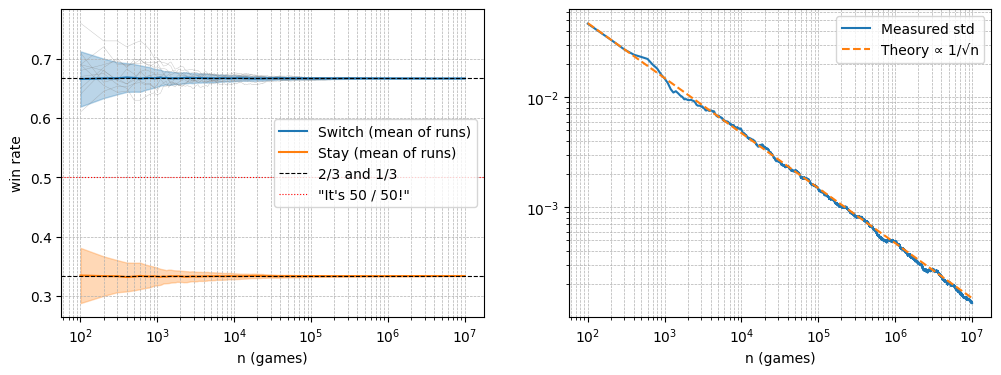

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Convergence: mean ± 1 std for both strategies, with a few individual runs in the background
ax1.plot(n_values, runs[:10].T, color='gray', lw=0.3, alpha=0.5)
ax1.plot(n_values, switch_mean, color='C0', label='Switch (mean of runs)')
ax1.fill_between(n_values, switch_mean - switch_std, switch_mean + switch_std, color='C0', alpha=0.3)
ax1.plot(n_values, stay_mean, color='C1', label='Stay (mean of runs)')
ax1.fill_between(n_values, stay_mean - switch_std, stay_mean + switch_std, color='C1', alpha=0.3)
ax1.axhline(P_SWITCH, color='black', ls='--', lw=0.8, label='2/3 and 1/3')
ax1.axhline(1 - P_SWITCH, color='black', ls='--', lw=0.8)
ax1.axhline(0.5, color='red', ls=':', lw=0.8, label='"It\'s 50 / 50!"')
ax1.set_xscale('log'); ax1.set_xlabel('n (games)'); ax1.set_ylabel('win rate'); ax1.legend()
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Measured std vs theory: sqrt(p(1 - p) / n)
ax2.loglog(n_values, switch_std, label='Measured std')
ax2.loglog(n_values, np.sqrt(P_SWITCH * (1 - P_SWITCH) / n_values), '--', label='Theory ∝ 1/√n')
ax2.set_xlabel('n (games)'); ax2.legend()
ax2.grid(True, which='both', linestyle='--', linewidth=0.5)


print(f'n = {n_values[-1]:.0e} : P(switch) = {switch_mean[-1]:.6f} ± {switch_std[-1]:.1e} (std of one run)')
print(f'Error on the mean of {N_RUNS} runs : ± {switch_std[-1] / np.sqrt(N_RUNS):.1e}')
print(f'Theory : 2/3 = {P_SWITCH:.6f} (difference : {switch_mean[-1] - P_SWITCH:+.1e})')